In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import matplotlib.ticker as ticker

from dask.diagnostics import ProgressBar

In [2]:
path_clim = '/jetfs/scratch/psplechtna/thesisdata/mse_climatology_4.0/'
filename_clim = 'mse_hourly_climatology.zarr'

In [3]:
clim = xr.open_mfdataset(path_clim+filename_clim, 
                             engine='zarr', concat_dim='time', combine='nested')

In [4]:
clim.mse

<xarray.DataArray 'mse' (time: 1, dayofyear: 109, hour: 24, height: 51,
                         latitude: 141, longitude: 720)> Size: 54GB
dask.array<getitem, shape=(1, 109, 24, 51, 141, 720), dtype=float32, chunksize=(1, 10, 1, 51, 141, 720), chunktype=numpy.ndarray>
Coordinates:
  * dayofyear  (dayofyear) int32 436B 136 137 138 139 140 ... 241 242 243 244
  * hour       (hour) int64 192B 0 1 2 3 4 5 6 7 8 ... 16 17 18 19 20 21 22 23
  * height     (height) float64 408B 20.0 50.0 100.0 ... 1.2e+04 1.5e+04 2e+04
  * latitude   (latitude) float64 1kB 90.0 89.5 89.0 88.5 ... 21.0 20.5 20.0
  * longitude  (longitude) float64 6kB -180.0 -179.5 -179.0 ... 179.0 179.5
Dimensions without coordinates: time

In [5]:
clim=clim.mse.sel(latitude=slice(90,45), time=0)

In [6]:
clim_50=clim.sel(height=50).mean(dim=['hour', 'dayofyear'])

In [7]:
clim_5000=clim.sel(height=5000).mean(dim=['hour', 'dayofyear'])

In [8]:
clim_vert = clim.sel(latitude=slice(90,60)).mean(dim=['latitude', 'longitude', 'hour', 'dayofyear'])

In [9]:
with ProgressBar():
    clim_vert = clim_vert.load()

[########################################] | 100% Completed | 107.37 s


In [10]:
with ProgressBar():
    clim_5000 = clim_5000.load()

[########################################] | 100% Completed | 58.67 s


In [11]:
with ProgressBar():
    clim_50 = clim_50.load()

[########################################] | 100% Completed | 100.43 s


In [12]:
clim_vert

<xarray.DataArray 'mse' (height: 51)> Size: 204B
array([289801.03, 289897.72, 290041.78, 290302.3 , 290656.4 , 291076.25,
       291556.12, 292090.3 , 292614.1 , 293135.75, 293672.38, 294168.  ,
       294631.9 , 295078.1 , 295505.06, 295887.47, 296224.2 , 296556.97,
       296925.12, 297208.16, 297500.2 , 297856.25, 298272.2 , 298862.25,
       299454.1 , 300044.03, 300625.72, 301196.84, 301760.78, 302326.62,
       302892.25, 303442.62, 303974.5 , 304508.3 , 305045.97, 305559.16,
       306056.25, 306908.38, 308069.97, 309182.44, 310316.03, 311550.06,
       312974.44, 314726.5 , 316984.5 , 319946.94, 323789.16, 331151.4 ,
       342534.12, 362057.9 , 398676.5 ], dtype=float32)
Coordinates:
  * height   (height) float64 408B 20.0 50.0 100.0 ... 1.2e+04 1.5e+04 2e+04

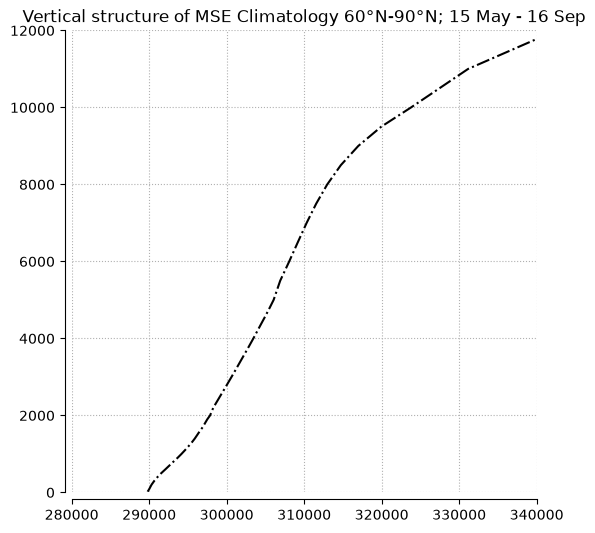

In [17]:
fig, ax = plt.subplots(figsize=(6,6))
ax.plot(clim_vert, clim_vert.height, '-.k')
ax.set_title('Vertical structure of MSE Climatology 60°N-90°N; 15 May - 16 Sep')
ax.grid(linestyle=':')
ax.set_ylim(0,12000)
ax.set_xlim(280000,340000)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))

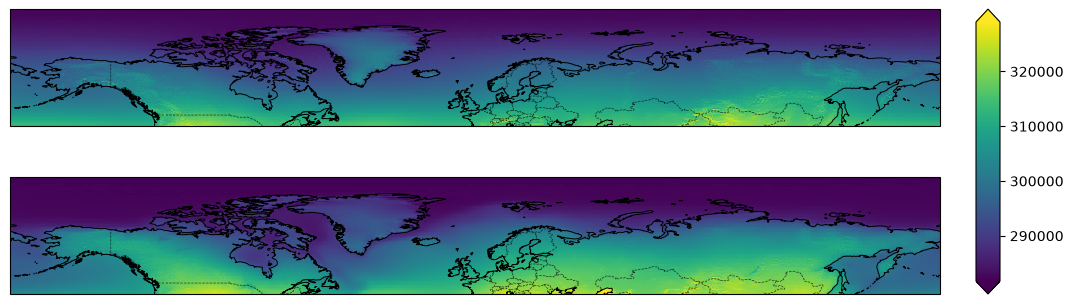

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(12,4), subplot_kw={'projection': ccrs.PlateCarree()})

contour=ax[0].pcolormesh(clim_5000.longitude, clim_5000.latitude, clim_5000)

contour=ax[1].pcolormesh(clim_50.longitude, clim_50.latitude, clim_50)

for axs in ax.flatten():
    axs.grid()
    axs.add_feature(cf.COASTLINE, linewidth=0.7)
    axs.add_feature(cf.BORDERS, linewidth=0.5, linestyle='--', alpha=0.7)

all_axes = ax[:]
bbox = mtransforms.Bbox.union([ax.get_position() for ax in all_axes])
cbar_width = 0.02
cbar_pad = 0.01
cax = fig.add_axes([
    bbox.x1 + cbar_pad + cbar_width,                       
    bbox.y0,
    cbar_width,
    bbox.height,          
])
cb = fig.colorbar(contour, orientation='vertical', cax=cax,
                 extend='both', shrink=0.8)      # arrows for out-of-range values
